# ДЗ: тонкая настройка DistilBERT на ag_news (Hugging Face Transformers)

Взята тема № 1 из задания: классификация новостей, 4 класса (World, Sports, Business, Sci/Tech).

**Этапы ноутбука (части 2 и 3 задания):**
0. Данные: `load_dataset` и стратифицированный train/validation split
1. Токенизация: `truncation=True`, `max_length=128` и динамический padding
2. Метрики: `accuracy` и `f1_macro`
3. Обучение через `Trainer`: lr=2e-5, batch=16, до 5 эпох, `EarlyStoppingCallback(patience=2)`
4. Итоговая таблица метрик
5. Confusion matrix и пары перепутанных классов
6. Анализ 5 случайных ошибок


In [1]:
%pip install -q -U transformers datasets evaluate accelerate scikit-learn matplotlib pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


## Конфигурация
`SMOKE` можно поменять на True: запускает мини-прогон (400 примеров, 1 эпоха), чтобы убедиться, что весь код работает.

In [2]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          EarlyStoppingCallback, Trainer, TrainingArguments, set_seed)

MODEL_NAME = "distilbert/distilbert-base-uncased"
DATASET_NAME = "fancyzhx/ag_news"   # то же, что "ag_news" в задании; актуальный id на Hub
OUT_DIR = "outputs_agnews"
SEED = 42

SMOKE = False          # True: быстрая проверка кода
TRAIN_SUBSET = None
MAX_EPOCHS = 5

ID2LABEL = {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}
LABEL2ID = {v: k for k, v in ID2LABEL.items()}

if SMOKE:
    TRAIN_SUBSET, MAX_EPOCHS = 400, 1

set_seed(SEED)
os.makedirs(OUT_DIR, exist_ok=True)
print("GPU доступен:", torch.cuda.is_available())

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


GPU доступен: True


## Вспомогательные функции
- `make_compute_metrics()` возвращает `compute_metrics` для `Trainer`: accuracy и **f1_macro** (`average="macro"`, среднее F1 по классам без учёта их размера). `Trainer` добавит префикс `eval_`, получатся `eval_accuracy` и `eval_f1_macro`.
- `top_confused_pairs()` находит самые частые ошибки «истинный vs предсказанный» по недиагональным ячейкам матрицы ошибок.
- `sample_errors()` выбирает n случайных ошибочных примеров (воспроизводимо по seed) и добавляет уверенность модели и длину текста: это пригодится для формулировки гипотез.

In [3]:
def make_compute_metrics():
    import evaluate
    acc = evaluate.load("accuracy")
    f1 = evaluate.load("f1")

    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        preds = np.argmax(logits, axis=-1)
        return {
            "accuracy": acc.compute(predictions=preds, references=labels)["accuracy"],
            "f1_macro": f1.compute(predictions=preds, references=labels, average="macro")["f1"],
        }
    return compute_metrics


def softmax(x):
    x = x - x.max(axis=1, keepdims=True)
    e = np.exp(x)
    return e / e.sum(axis=1, keepdims=True)


def top_confused_pairs(cm, id2label, k=3):
    cm = np.asarray(cm)
    pairs = []
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if i != j and cm[i, j] > 0:
                pairs.append((int(cm[i, j]), id2label[i], id2label[j]))
    pairs.sort(reverse=True)
    return pairs[:k]


def sample_errors(texts, y_true, y_pred, probs, id2label, n=5, seed=SEED, max_chars=100):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    wrong = np.where(y_true != y_pred)[0]
    if len(wrong) == 0:
        return []
    rng = np.random.default_rng(seed)
    chosen = rng.choice(wrong, size=min(n, len(wrong)), replace=False)
    return [{
        "text_100": texts[i][:max_chars].replace("\n", " "),
        "true": id2label[int(y_true[i])],
        "pred": id2label[int(y_pred[i])],
        "confidence": round(float(probs[i].max()), 3),
        "n_words": len(texts[i].split()),
    } for i in chosen]

## Этап 0. Данные
В ag_news есть только `train` (120 000) и `test` (7 600), готового validation нет. Поэтому validation вырезаем из train (10%, стратифицированно по классам), а `test` оставляем нетронутым как дополнительную финальную проверку.

In [4]:
raw = load_dataset(DATASET_NAME)
split = raw["train"].train_test_split(test_size=0.1, seed=SEED, stratify_by_column="label")
train_ds, val_ds, test_ds = split["train"], split["test"], raw["test"]

if SMOKE:
    val_ds, test_ds = val_ds.select(range(200)), test_ds.select(range(200))
if TRAIN_SUBSET:
    train_ds = train_ds.shuffle(seed=SEED).select(range(TRAIN_SUBSET))

print(f"train={len(train_ds)}  validation={len(val_ds)}  test={len(test_ds)}")
print(train_ds[0])

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

train=108000  validation=12000  test=7600
{'text': 'Three tied for lead at Southern Farm Bureau Classic John Senden carded a pair of eagles, Harrison Frazar shot a 31 on the front nine and Glen Day recorded seven birdies to finish Thursday #39;s first round of the ', 'label': 1}


## Этап 1. Токенизация
`truncation=True`, `max_length=128` по условию. Padding здесь не делаем: `DataCollatorWithPadding` дополняет каждый батч до самой длинной последовательности в нём, это быстрее, чем дополнять весь датасет до 128.

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def preprocess(batch):
    return tokenizer(batch["text"], truncation=True, max_length=128)

tok_train = train_ds.map(preprocess, batched=True)
tok_val = val_ds.map(preprocess, batched=True)
tok_test = test_ds.map(preprocess, batched=True)
collator = DataCollatorWithPadding(tokenizer=tokenizer)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/108000 [00:00<?, ? examples/s]

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

## Этапы 2–3. Модель и обучение
- `num_labels`, `id2label`, `label2id` задают размер классификационной головы и читаемые имена классов. `problem_type` определяется сам: метки целые, значит `single_label_classification` и `CrossEntropyLoss`.
- `eval_strategy="epoch"` и `save_strategy="epoch"` должны совпадать, это условие для `load_best_model_at_end=True`.
- `metric_for_best_model="f1_macro"`: лучшая модель выбирается по f1_macro, а не по loss.
- `EarlyStoppingCallback(early_stopping_patience=2)` останавливает обучение, если f1_macro не улучшается 2 оценки подряд.
- `processing_class=tokenizer` вместо устаревшего `tokenizer=`.

In [6]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(ID2LABEL), id2label=ID2LABEL, label2id=LABEL2ID)

training_args = TrainingArguments(
    output_dir=os.path.join(OUT_DIR, "checkpoints"),
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    num_train_epochs=MAX_EPOCHS,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    seed=SEED,
    report_to="none",
    logging_steps=100,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tok_train,
    eval_dataset=tok_val,
    processing_class=tokenizer,
    data_collator=collator,
    compute_metrics=make_compute_metrics(),
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)
trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.197227,0.185659,0.941167,0.941243
2,0.111293,0.207391,0.944833,0.944858
3,0.138181,0.226668,0.944000,0.944063
4,0.064918,0.280545,0.942500,0.942550


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=27000, training_loss=0.13444560538397896, metrics={'train_runtime': 1418.9155, 'train_samples_per_second': 304.458, 'train_steps_per_second': 19.029, 'total_flos': 1.0284133839721728e+16, 'train_loss': 0.13444560538397896, 'epoch': 4.0})

Благодаря EarlyStoppingCallback обучение остановлено на 4 эпохе, тк появилось снижение accuracy/f1 в параллели с ростом loss function.
Если есть необходимость оптимизировать параметры далее, можно поменять learning rate или сократить количество эпох.

## Этап 4. Итоговые метрики
Таблица для отчёта: `eval_accuracy`, `eval_f1_macro`, `eval_loss` на validation для лучшей модели (выбрана по f1_macro). Дополнительно метрики на нетронутом test.

In [7]:
val_metrics = trainer.evaluate(tok_val)
test_metrics = trainer.evaluate(tok_test, metric_key_prefix="test")

results = pd.DataFrame({
    "validation": [val_metrics["eval_accuracy"], val_metrics["eval_f1_macro"], val_metrics["eval_loss"]],
    "test (доп.)": [test_metrics["test_accuracy"], test_metrics["test_f1_macro"], test_metrics["test_loss"]],
}, index=["accuracy", "f1_macro", "loss"]).round(4)
display(results)
print("Эпох пройдено:", round(float(trainer.state.epoch), 2))

with open(os.path.join(OUT_DIR, "results.json"), "w", encoding="utf-8") as f:
    json.dump({"validation": results["validation"].to_dict(),
               "test": results["test (доп.)"].to_dict(),
               "epochs_run": float(trainer.state.epoch)}, f, indent=2, ensure_ascii=False)

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.064918,0.207391,4,0.944833,0.944858


[transformers] early stopping required metric_for_best_model, but did not find eval_f1_macro so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.064918,0.205805,4,0.942763,0.942789


,validation,test (доп.)
accuracy,0.9448,0.9428
f1_macro,0.9449,0.9428
loss,0.2074,0.2058


Эпох пройдено: 4.0


Метрики отличные. Accuracy и F1 Macro практически равны (0.94+). Это значит, что модель одинаково хорошо предсказывает все классы (нет перекоса в сторону мажоритарного класса, иначе F1 Macro был бы значительно ниже Accuracy).
Нет переобучения. Validation Loss (0.2074) и Test Loss (0.2058) практически идентичны. Accuracy на валидации (0.9448) и на тесте (0.9428) тоже почти не отличаются. Модель отлично обобщает данные.
Стабильность. Разница между train и val loss минимальна (хотя train loss, вероятно, ниже, но на скрине его не видно полностью, видно только кусок).

## Этап 5. Confusion matrix и перепутанные классы
Слева счётчики, справа матрица, нормированная по истинному классу (доля каждого класса, попавшая в каждое предсказание). `classification_report` показывает precision, recall и F1 по каждому классу, из него видно, какой класс тянет `f1_macro` вниз.

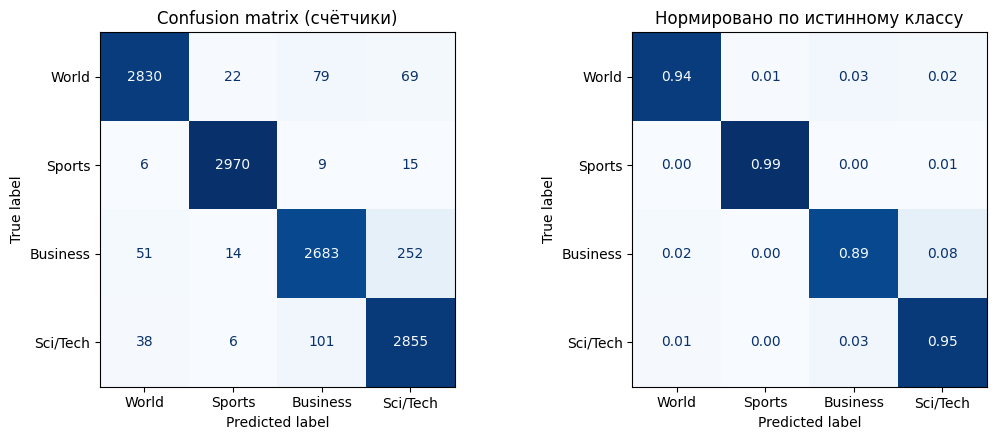

              precision    recall  f1-score   support

       World     0.9675    0.9433    0.9553      3000
      Sports     0.9861    0.9900    0.9880      3000
    Business     0.9342    0.8943    0.9138      3000
    Sci/Tech     0.8947    0.9517    0.9223      3000

    accuracy                         0.9448     12000
   macro avg     0.9456    0.9448    0.9449     12000
weighted avg     0.9456    0.9448    0.9449     12000

Топ перепутанных пар (истинный -> предсказанный):
  Business -> Sci/Tech: 252
  Sci/Tech -> Business: 101
  World -> Business: 79


In [8]:
pred_out = trainer.predict(tok_val)
logits, y_true = pred_out.predictions, pred_out.label_ids
y_pred = logits.argmax(axis=-1)
probs = softmax(logits)

labels_order = list(range(len(ID2LABEL)))
names = [ID2LABEL[i] for i in labels_order]
cm = confusion_matrix(y_true, y_pred, labels=labels_order)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(cm, display_labels=names).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix (счётчики)")
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=labels_order, normalize="true"),
                       display_labels=names).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
axes[1].set_title("Нормировано по истинному классу")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "confusion_matrix.png"), dpi=150)
plt.show()

print(classification_report(y_true, y_pred, target_names=names, digits=4))
print("Топ перепутанных пар (истинный -> предсказанный):")
for cnt, t, p in top_confused_pairs(cm, ID2LABEL, k=3):
    print(f"  {t} -> {p}: {cnt}")

**Задание на подумать.** Сравните `f1_macro` и `accuracy`. Датасет сбалансирован, поэтому ожидается, что они близки. Если `f1_macro` заметно ниже, найдите по `classification_report` классы с низким recall или precision. Выпишите 2–3 пары confused classes из блока выше и объясните, почему они путаются.

Ответ:
Топ перепутанных пар (истинный -> предсказанный):
  Business -> Sci/Tech: 252
  Sci/Tech -> Business: 101
  World -> Business: 79

Возможно, дело в том, что Sci/Tech в наше время является одним из самых актуальных направлений в бизнесе, и новости/информация по ним нередко пересекается.
Бизнес крупных международных компаний связан с географическими названиями и международной лексикой, здесь, наверное, ошибки по данной причине.

## Этап 6. Анализ 5 случайных ошибок
Колонки `confidence` (уверенность модели) и `n_words` (длина текста) помогают формулировать конкретные гипотезы: короткий текст, мало контекста; смешение тематик Business / Sci-Tech; редкая лексика; обрезка по `max_length=128` (проверьте по `n_words`); высокая уверенность при ошибке, возможно шум в разметке. Колонку `hypothesis` заполните сами, прочитав тексты целиком.

In [12]:
rows = sample_errors(val_ds["text"], y_true, y_pred, probs, ID2LABEL, n=5)
errors_df = pd.DataFrame(rows)
errors_df["hypothesis"] = ["Модель сбита с толку доминирующей политической и военной лексикой (терроризм, безопасность), игнорируя контекст авиаперевозок.",
    "Лексика природных явлений и катаклизмов (locusts, plagues) характерна для Sci/Tech, что перевешивает географические маркеры (Cairo) класса World.",
    "Модель переоценивает упоминание технологических компаний (Google, Apple), игнорируя явные финансовые маркеры (Wall Street, stocks).",
    "Из-за плотности медицинских терминов (biotechnology, drug) модель игнорирует корпоративный контекст (компания, повестка от Минюста).",
    "Модель ошибочно относит медиа-контент (Forbes Magazine) к Sci/Tech, упуская из виду финансовые маркеры (wealth, richest)"]   # <- заполните вручную
errors_df.to_csv(os.path.join(OUT_DIR, "errors_sample.csv"), index=False, encoding="utf-8")
pd.set_option("display.max_colwidth", 120)
display(errors_df)

# полные тексты, чтобы удобнее писать гипотезы
idx = np.where(y_true != y_pred)[0]
rng = np.random.default_rng(SEED)
for i in rng.choice(idx, size=min(5, len(idx)), replace=False):
    print(f"[{ID2LABEL[int(y_true[i])]} -> {ID2LABEL[int(y_pred[i])]}] {val_ds['text'][i]}\n")

,text_100,true,pred,confidence,n_words,hypothesis
0,9/11 commissioner: Threat of airplane suicide bombing has &lt;b&gt;...&lt;/b&gt; A member of the 9/1,Business,World,0.945,41,"Модель сбита с толку доминирующей политической и военной лексикой (терроризм, безопасность), игнорируя контекст авиа..."
1,Pink Locusts from North Africa Swarm Through Cairo CAIRO (Reuters) - Swarms of pink locusts swept t,World,Sci/Tech,0.799,36,"Лексика природных явлений и катаклизмов (locusts, plagues) характерна для Sci/Tech, что перевешивает географические ..."
2,"Stocks Close Higher Before Holiday (Reuters) Reuters - U.S. stocks closed higher on\Wednesday, with",Sci/Tech,Business,0.956,33,"Модель переоценивает упоминание технологических компаний (Google, Apple), игнорируя явные финансовые маркеры (Wall S..."
3,InterMune Gets Subpoena from Justice Dept (Reuters) Reuters - Biotechnology company InterMune Inc. \,Business,Sci/Tech,0.877,40,"Из-за плотности медицинских терминов (biotechnology, drug) модель игнорирует корпоративный контекст (компания, повес..."
4,"Wealth in America In what has become an annual ritual, Forbes Magazine has released its ""400 Richest",Sci/Tech,Business,0.997,53,"Модель ошибочно относит медиа-контент (Forbes Magazine) к Sci/Tech, упуская из виду финансовые маркеры (wealth, rich..."


[Business -> World] 9/11 commissioner: Threat of airplane suicide bombing has &lt;b&gt;...&lt;/b&gt; A member of the 9/11 commission told House lawmakers Wednesday that the risk of an airline passenger detonating a suicide bomb has increased as a result of security precautions to prevent hijackings.

[World -> Sci/Tech] Pink Locusts from North Africa Swarm Through Cairo  CAIRO (Reuters) - Swarms of pink locusts swept through the  Egyptian capital on Wednesday, evoking the biblical description  of the plagues which struck in the time of Moses.

[Sci/Tech -> Business] Stocks Close Higher Before Holiday (Reuters) Reuters - U.S. stocks closed higher on\Wednesday, with technology stocks Google Inc.  and\Apple Computer Inc.  leading the way in quiet trading\as Wall Street wound down for Thanksgiving.

[Business -> Sci/Tech] InterMune Gets Subpoena from Justice Dept (Reuters) Reuters - Biotechnology company InterMune Inc. \on Tuesday said it received a subpoena from the U.S. Department\of Jus